In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv("../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv")



In [4]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [5]:
print(df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

float64
Missing values: 0


In [6]:
df_ml = df.drop(columns=["customerID"])

In [7]:
X = df_ml.drop(columns=["Churn"])

y = df_ml["Churn"]

In [8]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [9]:
X_encoded = pd.get_dummies(X, drop_first=True)

In [10]:
print("Encoded X shape:", X_encoded.shape)

Encoded X shape: (7043, 30)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [14]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [15]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:20])

print("Number of predictions:", len(y_pred))

['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']
Number of predictions: 1409


In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8062455642299503


In [17]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[925 110]
 [163 211]]


In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.6573208722741433
Recall: 0.5641711229946524
F1-score: 0.6071942446043166


In [19]:
y_prob = model.predict_proba(X_test_scaled)

print(y_prob[:5])

[[0.954426   0.045574  ]
 [0.31643649 0.68356351]
 [0.94347664 0.05652336]
 [0.59271983 0.40728017]
 [0.97827959 0.02172041]]


In [20]:
print(model.classes_)

['No' 'Yes']


In [21]:
y_prob_yes = y_prob[:, 1]

In [22]:
print(y_prob_yes[:5])

[0.045574   0.68356351 0.05652336 0.40728017 0.02172041]


In [23]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob_yes)

print("ROC-AUC:", auc)

ROC-AUC: 0.8418093983311374


## ROC-AUC

- ROC-AUC was used to evaluate the model's ability to distinguish between customers who churn and customers who do not churn.
- The model achieved a ROC-AUC score of approximately 0.842.
- ROC-AUC evaluates the model across different classification thresholds.
- `predict_proba()` was used because ROC-AUC requires probability scores.
- Since `model.classes_` returned ['No', 'Yes'], `y_prob[:, 1]` represents the probability of Churn = Yes.
- Accuracy and ROC-AUC measure different aspects of model performance.

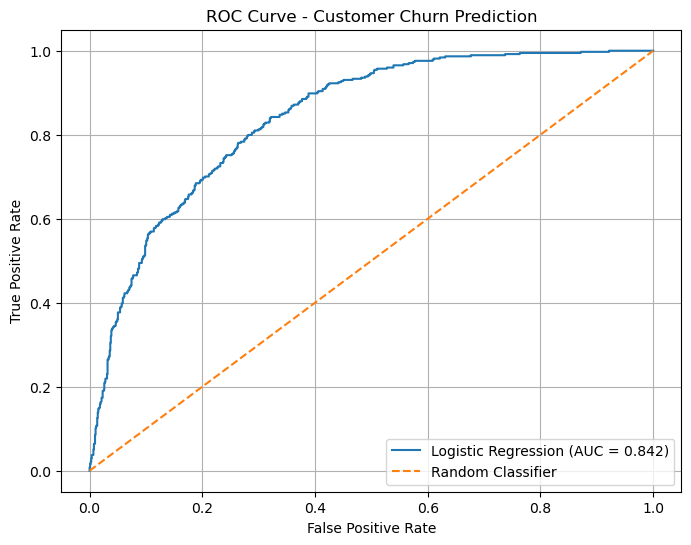

In [24]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_yes,
    pos_label="Yes"
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Customer Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.show()

In [25]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Probability of Churn = Yes
threshold = 0.3

y_pred_03 = np.where(
    y_prob_yes >= threshold,
    "Yes",
    "No"
)

cm_03 = confusion_matrix(
    y_test,
    y_pred_03,
    labels=["No", "Yes"]
)

precision_03 = precision_score(
    y_test,
    y_pred_03,
    pos_label="Yes"
)

recall_03 = recall_score(
    y_test,
    y_pred_03,
    pos_label="Yes"
)

f1_03 = f1_score(
    y_test,
    y_pred_03,
    pos_label="Yes"
)

print("Threshold:", threshold)
print("\nConfusion Matrix:")
print(cm_03)

print("\nPrecision:", precision_03)
print("Recall:", recall_03)
print("F1-score:", f1_03)

Threshold: 0.3

Confusion Matrix:
[[774 261]
 [ 92 282]]

Precision: 0.5193370165745856
Recall: 0.7540106951871658
F1-score: 0.6150490730643402


In [26]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Logistic Regression: use the scaled features
log_pred = model.predict(X_test_scaled)
log_prob = model.predict_proba(X_test_scaled)[:, 1]

# Random Forest: use the encoded, unscaled features
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Compare the models
results = []

for name, pred, prob in [
    ("Logistic Regression", log_pred, log_prob),
    ("Random Forest", rf_pred, rf_prob)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, pos_label="Yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, pos_label="Yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Yes").astype(int), prob
        )
    })

results_df = pd.DataFrame(results).round(3)
print(results_df)


                 Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0  Logistic Regression     0.806      0.657   0.564     0.607    0.842
1        Random Forest     0.788      0.625   0.500     0.556    0.825


# Day 14 Findings — Machine Learning Model Comparison

## 1. What I Completed
- Reviewed the Logistic Regression model and its evaluation metrics.
- Compared Logistic Regression with Random Forest.
- Evaluated both models using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Reviewed the classification threshold and its effect on Recall and Precision.
- Selected Logistic Regression as the current baseline model.

## 2. Model Comparison

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 80.62% | 78.80% |
| Precision | 65.73% | 62.50% |
| Recall | 56.42% | 50.00% |
| F1-score | 60.72% | 55.60% |
| ROC-AUC | 0.842 | 0.825 |

**Finding:** Logistic Regression performed better than Random Forest across all five evaluation metrics in this comparison.

## 3. Classification Threshold

The default classification threshold was 0.5. I also evaluated Logistic Regression using a threshold of 0.3.

| Metric | Threshold 0.5 | Threshold 0.3 |
|---|---:|---:|
| Precision | 65.73% | 51.93% |
| Recall | 56.42% | 75.40% |
| F1-score | 60.72% | 61.50% |

**Finding:** Lowering the threshold to 0.3 increased Recall from 56.42% to 75.40%, while Precision decreased from 65.73% to 51.93%.

This is useful because the business objective is to identify more customers who may leave the company, even if some customers are incorrectly flagged as potential churners.

## 4. Key Machine Learning Concepts
- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** Among customers predicted to churn, the proportion who actually churned.
- **Recall:** Among customers who actually churned, the proportion identified by the model.
- **F1-score:** A combined measure of Precision and Recall.
- **ROC-AUC:** Measures how well the model distinguishes between the two classes across different thresholds.
- **Classification threshold:** The probability cutoff used to classify a customer as likely to churn.

## 5. Conclusion
Logistic Regression is the better baseline model among the two models tested. A threshold of 0.3 provides higher Recall and may be more suitable when identifying potential churners is the priority. The final threshold should be selected based on business needs and validated appropriately.

## 6. Next Step
Start building an interactive **Power BI dashboard** to present the customer churn analysis, key business insights, and important KPIs.